WINE DATASET
Dataset Shape: (178, 13)
Number of Features: 13

BASELINE MODEL (ALL FEATURES)
Accuracy using all features: 1.0000

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


Top Features:
                         Feature  Importance
9                color_intensity    0.187404
6                     flavanoids    0.168373
12                       proline    0.157024
0                        alcohol    0.108171
10                           hue    0.094966
11  od280/od315_of_diluted_wines    0.089898
5                  total_phenols    0.051274
4                      magnesium    0.035210
1                     malic_acid    0.030246
8  

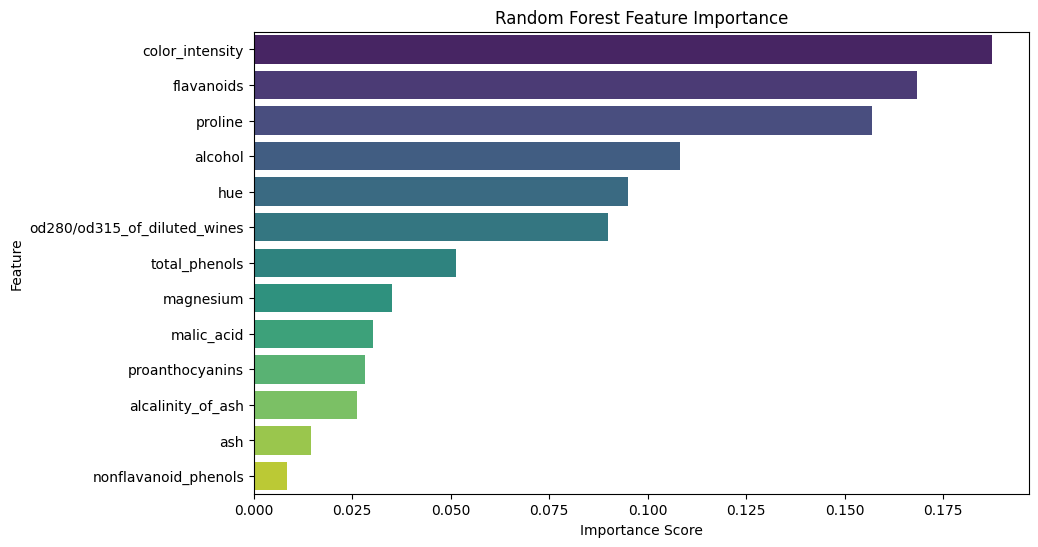


Top 5 Features:
['color_intensity', 'flavanoids', 'proline', 'alcohol', 'hue']

MODEL USING TOP 5 FEATURES
Accuracy using top 5 features: 1.0000

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



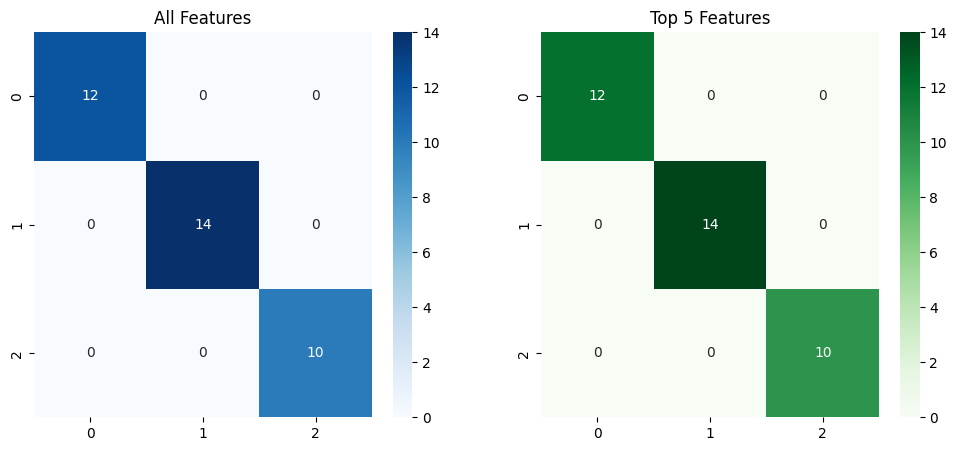


MODEL COMPARISON
                            Model  Accuracy  Number of Features
0    Random Forest (All Features)       1.0                  13
1  Random Forest (Top 5 Features)       1.0                   5


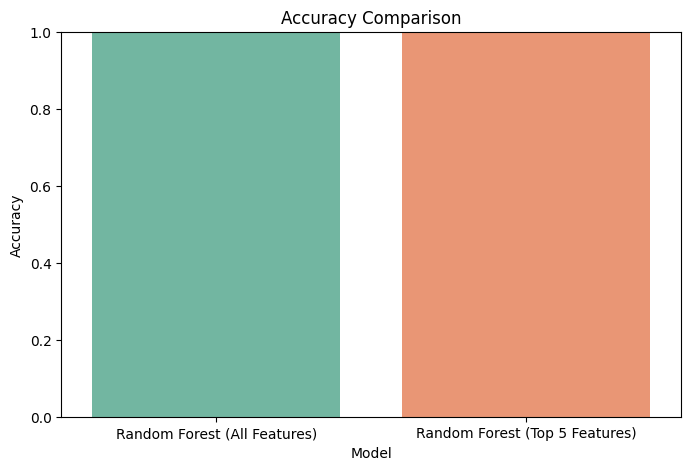


INTERPRETATION

Accuracy Difference: 0.0000

Impact on Accuracy:
- Compare the two accuracy scores.
- If the difference is small, most information
  is contained in the top features.

Impact on Simplicity:
- Reduced from 13 features to 5 features.
- Model becomes easier to use and maintain.

Impact on Interpretability:
- Easier to explain predictions.
- Focuses on only the most influential variables.
- More understandable for business and research purposes.


CONCLUSION

Using only the top five features produced performance
very similar to the baseline model while significantly
reducing model complexity.

This demonstrates that feature selection can simplify
the model without substantially affecting predictive
performance.



In [1]:
# ==========================================================
# ASSIGNMENT 7
# Random Forest Feature Selection
# Dataset: Wine Dataset
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ==========================================================
# 1. LOAD DATASET
# ==========================================================

print("="*60)
print("WINE DATASET")
print("="*60)

wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])

# ==========================================================
# 2. TRAIN TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================================
# 3. BASELINE RANDOM FOREST USING ALL FEATURES
# ==========================================================

print("\n" + "="*60)
print("BASELINE MODEL (ALL FEATURES)")
print("="*60)

rf_all = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_all.fit(X_train, y_train)

y_pred_all = rf_all.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    y_pred_all
)

print(f"Accuracy using all features: {baseline_accuracy:.4f}")

print("\nClassification Report")
print(classification_report(
    y_test,
    y_pred_all
))

# ==========================================================
# 4. FEATURE IMPORTANCE
# ==========================================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_all.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop Features:")
print(feature_importance)

# ==========================================================
# 5. FEATURE IMPORTANCE VISUALIZATION
# ==========================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

# ==========================================================
# 6. SELECT TOP 5 FEATURES
# ==========================================================

top_features = feature_importance.head(5)["Feature"].tolist()

print("\nTop 5 Features:")
print(top_features)

X_top5 = X[top_features]

# ==========================================================
# 7. TRAIN TEST SPLIT FOR TOP FEATURES
# ==========================================================

X_train_top, X_test_top, y_train_top, y_test_top = train_test_split(
    X_top5,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================================
# 8. RANDOM FOREST USING TOP 5 FEATURES
# ==========================================================

print("\n" + "="*60)
print("MODEL USING TOP 5 FEATURES")
print("="*60)

rf_top5 = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_top5.fit(X_train_top, y_train_top)

y_pred_top5 = rf_top5.predict(X_test_top)

top5_accuracy = accuracy_score(
    y_test_top,
    y_pred_top5
)

print(f"Accuracy using top 5 features: {top5_accuracy:.4f}")

print("\nClassification Report")
print(classification_report(
    y_test_top,
    y_pred_top5
))

# ==========================================================
# 9. CONFUSION MATRICES
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12,5)
)

cm1 = confusion_matrix(
    y_test,
    y_pred_all
)

sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title("All Features")

cm2 = confusion_matrix(
    y_test_top,
    y_pred_top5
)

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title("Top 5 Features")

plt.show()

# ==========================================================
# 10. COMPARISON TABLE
# ==========================================================

comparison = pd.DataFrame({
    "Model": [
        "Random Forest (All Features)",
        "Random Forest (Top 5 Features)"
    ],
    "Accuracy": [
        baseline_accuracy,
        top5_accuracy
    ],
    "Number of Features": [
        X.shape[1],
        5
    ]
})

print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)

print(comparison)

# ==========================================================
# 11. ACCURACY COMPARISON PLOT
# ==========================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    palette="Set2"
)

plt.title("Accuracy Comparison")
plt.ylim(0,1)

plt.show()

# ==========================================================
# 12. INTERPRETATION
# ==========================================================

print("\n" + "="*60)
print("INTERPRETATION")
print("="*60)

accuracy_drop = baseline_accuracy - top5_accuracy

print(f"""
Accuracy Difference: {accuracy_drop:.4f}

Impact on Accuracy:
- Compare the two accuracy scores.
- If the difference is small, most information
  is contained in the top features.

Impact on Simplicity:
- Reduced from {X.shape[1]} features to 5 features.
- Model becomes easier to use and maintain.

Impact on Interpretability:
- Easier to explain predictions.
- Focuses on only the most influential variables.
- More understandable for business and research purposes.
""")

# ==========================================================
# 13. CONCLUSION
# ==========================================================

print("\n" + "="*60)
print("CONCLUSION")
print("="*60)

if top5_accuracy >= baseline_accuracy - 0.05:
    conclusion = """
Using only the top five features produced performance
very similar to the baseline model while significantly
reducing model complexity.

This demonstrates that feature selection can simplify
the model without substantially affecting predictive
performance.
"""
else:
    conclusion = """
Using all features achieved noticeably better accuracy.

Although feature selection improved interpretability
and simplicity, some predictive information was lost
by removing features.
"""

print(conclusion)